# Session 18 Solutions: Confidence Intervals and Hypothesis Tests

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(28)
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")

rng = np.random.default_rng(30)
ab = pd.read_csv(DATA_URL + "ab_test.csv")

## In-Class Exercises

### In-Class Exercise 1: English Interval

In [2]:
e = exams["english"]
se = e.std() / np.sqrt(len(e))
print(stats.t.interval(0.95, df=len(e) - 1, loc=e.mean(), scale=se))

(np.float64(66.58652254288641), np.float64(67.92547745711359))


### In-Class Exercise 2: Churn Rate

In [3]:
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
m = churn[churn["contract"] == "Month-to-month"]
p = (m["churn"] == "Yes").mean()
se = np.sqrt(p * (1 - p) / len(m))
print(round(p, 3), round(p - 1.96 * se, 3), round(p + 1.96 * se, 3))

0.451 0.422 0.481


### In-Class Exercise 3: Devices

In [4]:
table = pd.crosstab(ab["device"], ab["converted"])
print(table)
print(stats.chi2_contingency(table)[1])

converted  False  True 
device                 
Desktop     1333    201
Mobile      2192    274
0.06528614440186319


### In-Class Exercise 4: Sample Size Matters

In [5]:
small = ab.head(200)
print(pd.crosstab(small["group"], small["converted"]))
print(round(stats.chi2_contingency(pd.crosstab(small["group"], small["converted"]))[1], 3))

converted  False  True 
group                  
A             99     10
B             76     15
0.18


## Part A: Basic

### Exercise 1: Interval for Sleep

In [6]:
s = exams["sleep_hours"]
low, high = stats.t.interval(0.95, df=len(s) - 1, loc=s.mean(), scale=s.std() / np.sqrt(len(s)))
print(round(low, 2), round(high, 2))
# We are 95 percent confident that students in this population sleep on average between these two values per night.

6.99 7.18


### Exercise 2: Passed by Class

In [7]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
table = pd.crosstab(exams["class"], exams["passed"])
print(table)
print(round(stats.chi2_contingency(table)[1], 3))

passed  False  True 
class               
A          44     40
B          55     43
C          50     47
D          61     51
E          65     44
0.789


## Part B: Intermediate

### Exercise 3: Intervals by Class

`stats.t.ppf(0.975, df)` gives the multiplier that replaces 1.96 for a sample of that size.

  class   mean  margin
0     A  57.58    2.86
1     B  56.36    2.54
2     C  57.86    2.89
3     D  56.12    2.53
4     E  55.92    2.44


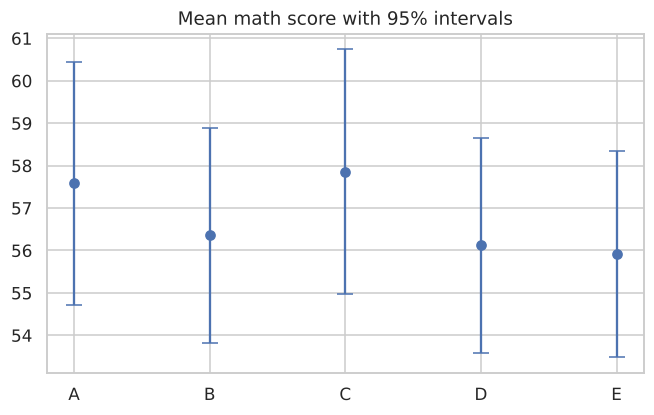

In [8]:
rows = []
for c, g in exams.groupby("class"):
    m = g["math"].mean()
    margin = stats.t.ppf(0.975, len(g) - 1) * g["math"].std() / np.sqrt(len(g))
    rows.append((c, m, margin))
ci = pd.DataFrame(rows, columns=["class", "mean", "margin"])
print(ci.round(2))
plt.errorbar(ci["class"], ci["mean"], yerr=ci["margin"], fmt="o", capsize=5)
plt.title("Mean math score with 95% intervals")
plt.show()

### Exercise 4: Salaries of Two Cities

In [9]:
emp = pd.read_csv(DATA_URL + "employees.csv")
a = emp.loc[emp["city"] == "Amman", "monthly_salary"]
b = emp.loc[emp["city"] == "Beirut", "monthly_salary"]
res = stats.ttest_ind(a, b, equal_var=False)
d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print(round(a.mean()), round(b.mean()), round(res.pvalue, 3), round(d, 2))

2205 1987 0.009 0.38


## Part C: Challenge

### Exercise 5: Power by Simulation

Small experiments usually miss a real two-point improvement. Planning the sample size before an experiment avoids wasted tests.

In [10]:
def power(n, pa=0.10, pb=0.12, runs=1000):
    hits = 0
    for _ in range(runs):
        ca, cb = rng.binomial(n, pa), rng.binomial(n, pb)
        table = [[ca, n - ca], [cb, n - cb]]
        hits += stats.chi2_contingency(table)[1] < 0.05
    return hits / runs

for n in [500, 2000, 5000]:
    print(n, power(n))

500 0.16
2000 0.523
5000 0.885


## Part D: Cumulative Project: Exam Scores Study

### Exercise 6: Exam Scores Study: Part 3

In [11]:
for col in ["math", "physics", "english"]:
    s = exams[col]
    print(col, np.round(stats.t.interval(0.95, len(s) - 1, s.mean(), s.std() / np.sqrt(len(s))), 2))
p, n = exams["passed"].mean(), len(exams)
print("Pass rate:", round(p, 3), np.round([p - 1.96 * np.sqrt(p * (1 - p) / n), p + 1.96 * np.sqrt(p * (1 - p) / n)], 3))
for name, g in exams.groupby(exams["study_hours_week"] > 10):
    s = g["math"]
    print("Study > 10:" if name else "Study <= 10:", np.round(stats.t.interval(0.95, len(s) - 1, s.mean(), s.std() / np.sqrt(len(s))), 2))
# Students who study more than 10 hours a week score clearly higher in math; the ranges do not overlap.
# About 45 percent of students pass, and we can be fairly sure the true rate is between about 41 and 49 percent.
# The averages are precise because 500 students took part, but they describe this group of students only.

math [55.54 57.87]
physics [50.74 52.74]
english [66.59 67.93]
Pass rate: 0.45 [0.406 0.494]
Study <= 10: [52.96 55.36]
Study > 10: [64.52 69.52]


### Exercise 7: Exam Scores Study: Final Part

In [12]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
a = exams.loc[exams["sleep_hours"] >= 8, "math"]
b = exams.loc[exams["sleep_hours"] < 6, "math"]
res = stats.ttest_ind(a, b, equal_var=False)
d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print("Sleep:", round(a.mean(), 1), round(b.mean(), 1), round(res.pvalue, 4), round(d, 2))
table = pd.crosstab(exams["study_hours_week"] > 10, exams["passed"])
print("Study and passing p:", stats.chi2_contingency(table)[1])
print(stats.f_oneway(*[g["english"] for _, g in exams.groupby("class")]))
# Students who study more pass much more often, and study time is the habit most linked to good results.
# Students who sleep at least 8 hours score clearly higher in math than those who sleep less than 6.
# The five classes perform similarly, so the differences come from students' habits more than from their class.
# Limitation: this is observational data, so it shows associations, not proven causes.

Sleep: 60.8 53.5 0.0005 0.53
Study and passing p: 1.1199032785615308e-17
F_onewayResult(statistic=np.float64(0.3614109814565196), pvalue=np.float64(0.836083003155498))


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | SE is divided by the square root of n, and sqrt(4) = 2. |
| 2 | B | Means of large samples are bell-shaped whatever the population's shape. |
| 3 | B | H0 is the no-effect starting point. |
| 4 | B | The p-value is computed assuming H0 is true. |
| 5 | B | Large samples make tiny effects significant; report the effect size. |